In [1]:
# 1) Design model (input, output size, forward pass) 
# 2) Construct loss and optimizer 
# 3) Training loop 
# - forward pass: compute prediction and loss
# - backward pass: gradients 
# - update weights 

epoch: 10, loss = 4287.3540
epoch: 20, loss = 3202.7737
epoch: 30, loss = 2417.3806
epoch: 40, loss = 1848.0687
epoch: 50, loss = 1435.0050
epoch: 60, loss = 1135.0483
epoch: 70, loss = 917.0550
epoch: 80, loss = 758.5129
epoch: 90, loss = 643.1309
epoch: 100, loss = 559.1078


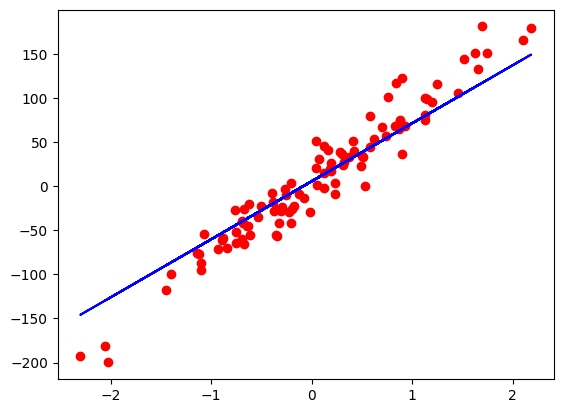

In [2]:
import torch 
import torch.nn as nn
import numpy as np
from sklearn import datasets 
import matplotlib.pyplot as plt

# 0. prepare data 
# generate data
X_numpy, y_numpy = datasets.make_regression(n_samples=100, n_features=1, noise=20, random_state=1) 

# convert to torch tensors, convert double (default np type) to float
X = torch.from_numpy(X_numpy.astype(np.float32))
y = torch.from_numpy(y_numpy.astype(np.float32))

# reshape y to be a column vector [[val1], [val2], ...] instead of [val1, val2, ...]
y = y.view(y.shape[0], 1)

n_samples, n_features = X.shape

# 1. model, single layer 
input_size = n_features
output_size = 1
model = nn.Linear(input_size, output_size)

# 2. loss and optimizer, mean squared error and stochastic gradient descent
criterion = nn.MSELoss()
learning_rate = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

# 3. training loop
num_epochs = 100
for epoch in range(num_epochs): 
    # forward pass
    y_predicted = model(X) 
    loss = criterion(y_predicted, y) 

    # backward pass
    loss.backward()

    # update
    optimizer.step()

    # zero gradients
    optimizer.zero_grad()

    if(epoch + 1) % 10 == 0: 
        print(f'epoch: {epoch+1}, loss = {loss.item():.4f}')

# plot, detach to remove gradient tracking
predicted = model(X).detach().numpy()

# red dots
plt.plot(X_numpy, y_numpy, 'ro')
plt.plot(X_numpy, predicted, 'b')
plt.show()